<a href="https://colab.research.google.com/github/AdityaAnand-Vi/SGDR_implementation/blob/main/SGDR_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, json, time, math, random, shutil
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)          # must say cuda; on CPU one epoch takes about 90 s instead of 2 s

# results are written to Google Drive so a Colab disconnect does not lose finished runs
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/SGDR_Project"
except ImportError:
    PROJECT_DIR = "./SGDR_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# ---------------- experiment configuration ----------------
EPOCHS      = 70          # with T0=10, T_mult=2 the cycles end at epochs 10, 30, 70
SEEDS       = [0, 1, 2]   # main comparison
ABL_SEEDS   = [0]         # ablations (raise to [0, 1, 2] if time allows)
BATCH       = 128
PRINT_EVERY = 1           # 1 = print every epoch; 10 = print every 10th epoch
FORCE_RERUN = False       # False: runs that are already saved are replayed from disk instead of retrained

ARCH, LR0, OUT = "cnn", 0.01, None

def use_setup(arch, lr0):
    """Select network and initial LR. Each setup gets its own results folder."""
    global ARCH, LR0, OUT
    ARCH, LR0 = arch, lr0
    OUT = os.path.join(PROJECT_DIR, "v2" if arch == "cnn" else f"v2_{arch}")
    os.makedirs(OUT, exist_ok=True)
    print(f"setup: arch={ARCH}, eta_max={LR0}, results folder={OUT}")

use_setup("cnn", 0.01)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

device: cuda
Mounted at /content/drive
setup: arch=cnn, eta_max=0.01, results folder=/content/drive/MyDrive/SGDR_Project/v2


In [2]:
# CIFAR-10 raw images; a copy on Drive saves the slow download after a runtime restart
DATA_BACKUP = os.path.join(PROJECT_DIR, "data")
if os.path.isdir(DATA_BACKUP) and not os.path.isdir("./data"):
    shutil.copytree(DATA_BACKUP, "./data")
ds_train = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
ds_test  = torchvision.datasets.CIFAR10("./data", train=False, download=True)
if not os.path.isdir(DATA_BACKUP):
    shutil.copytree("./data", DATA_BACKUP)

MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)   # per-channel statistics of CIFAR-10
mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
std  = torch.tensor(STD,  device=device).view(1, 3, 1, 1)

def to_gpu(raw_uint8):
    """(N,32,32,3) uint8 -> normalised float tensor (N,3,32,32) on the GPU."""
    x = torch.from_numpy(raw_uint8).to(device).permute(0, 3, 1, 2).float().div(255)
    return (x - mean) / std

X_all,  y_all  = to_gpu(ds_train.data), torch.tensor(ds_train.targets, device=device)
X_test, y_test = to_gpu(ds_test.data),  torch.tensor(ds_test.targets,  device=device)

# fixed 45k / 5k split (same split for every run)
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g).tolist()
val_idx, tr_idx = perm[:5000], perm[5000:]
tr_t, val_t = torch.tensor(tr_idx, device=device), torch.tensor(val_idx, device=device)
val_labels, test_labels = np.array(ds_train.targets)[val_idx], np.array(ds_test.targets)

def augment(x):
    """Random crop (pad 4, reflect) + horizontal flip, independently for every image in the batch."""
    B = x.size(0)
    flip = torch.rand(B, device=device) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (B,), device=device)          # random vertical offset 0..8
    j = torch.randint(0, 9, (B,), device=device)          # random horizontal offset 0..8
    ar = torch.arange(32, device=device)
    rows, cols = i.view(B, 1) + ar.view(1, 32), j.view(B, 1) + ar.view(1, 32)
    # advanced indexing picks a different 32x32 window for every image
    return xp[torch.arange(B, device=device).view(B, 1, 1, 1), torch.arange(3, device=device).view(1, 3, 1, 1),
              rows.view(B, 1, 32, 1), cols.view(B, 1, 1, 32)]

class GPULoader:
    """Minimal replacement for DataLoader: shuffles, batches and (optionally) augments on the GPU."""
    def __init__(self, X, y, batch, shuffle, aug):
        self.X, self.y, self.batch, self.shuffle, self.aug = X, y, batch, shuffle, aug
    def __len__(self): return math.ceil(len(self.X) / self.batch)
    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, device=device) if self.shuffle else torch.arange(n, device=device)
        for k in range(0, n, self.batch):
            b = idx[k:k + self.batch]
            x = self.X[b]
            yield (augment(x) if self.aug else x), self.y[b]

train_loader = GPULoader(X_all[tr_t],  y_all[tr_t],  BATCH, shuffle=True,  aug=True)
val_loader   = GPULoader(X_all[val_t], y_all[val_t], 500,   shuffle=False, aug=False)
test_loader  = GPULoader(X_test,       y_test,       500,   shuffle=False, aug=False)
xb, yb = next(iter(train_loader))
print(f"train {len(tr_idx)} | val {len(val_idx)} | test {len(test_labels)} | {len(train_loader)} batches/epoch | "
      f"batch {tuple(xb.shape)}, mean {xb.mean().item():.2f}, std {xb.std().item():.2f}")

100%|██████████| 170M/170M [49:06<00:00, 57.9kB/s]


train 45000 | val 5000 | test 10000 | 352 batches/epoch | batch (128, 3, 32, 32), mean 0.01, std 0.99


In [3]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        return self.fc2(F.relu(self.fc1(x)))

class _Block(nn.Module):
    """Pre-activation residual block: BN-ReLU-Conv-BN-ReLU-Conv + skip connection."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(cin);  self.conv1 = nn.Conv2d(cin,  cout, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout); self.conv2 = nn.Conv2d(cout, cout, 3, 1,      1, bias=False)
        # 1x1 conv on the skip path only when the shape changes
        self.short = nn.Conv2d(cin, cout, 1, stride, 0, bias=False) if (stride != 1 or cin != cout) else None
    def forward(self, x):
        o = F.relu(self.bn1(x))
        sc = x if self.short is None else self.short(o)
        return self.conv2(F.relu(self.bn2(self.conv1(o)))) + sc

class WideResNet(nn.Module):
    def __init__(self, depth=16, k=4, num_classes=10):
        super().__init__()
        n = (depth - 4) // 6                       # blocks per stage
        w = [16, 16 * k, 32 * k, 64 * k]           # channel widths
        self.conv1 = nn.Conv2d(3, w[0], 3, 1, 1, bias=False)
        layers, cin = [], w[0]
        for cout, stride in zip(w[1:], (1, 2, 2)):
            for j in range(n):
                layers.append(_Block(cin, cout, stride if j == 0 else 1)); cin = cout
        self.blocks = nn.Sequential(*layers)
        self.bn = nn.BatchNorm2d(cin); self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        x = F.relu(self.bn(self.blocks(self.conv1(x))))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

def make_model():
    if ARCH == "cnn": return CIFAR10CNN()
    _, d, k = ARCH.split("-")
    return WideResNet(int(d), int(k))

print(f"{ARCH}: {sum(p.numel() for p in make_model().parameters()) / 1e6:.2f}M parameters")

cnn: 0.55M parameters


In [4]:
class SGDRScheduler:
    """Cosine annealing with warm restarts. Call step() once per BATCH, before optimizer.step()."""
    def __init__(self, optimizer, steps_per_epoch, T_0=10, T_mult=2, eta_max=0.01, eta_min=1e-5):
        self.optimizer = optimizer
        self.steps_per_epoch = steps_per_epoch
        self.T_0 = T_0
        self.T_mult = T_mult
        self.eta_max = eta_max
        self.eta_min = eta_min
        self.cycle_length = T_0 * steps_per_epoch    # length of the current run, in batches
        self.cycle_step = 0                          # batches since the last restart
        self.total_steps = 0

    def step(self):
        # T_cur / T_i = cycle_step / cycle_length
        progress = self.cycle_step / self.cycle_length
        lr = self.eta_min + 0.5 * (self.eta_max - self.eta_min) * (1 + math.cos(math.pi * progress))
        for group in self.optimizer.param_groups:
            group["lr"] = lr
        self.cycle_step += 1
        self.total_steps += 1
        if self.cycle_step >= self.cycle_length:     # run finished -> warm restart, next run is T_mult times longer
            self.cycle_step = 0
            self.cycle_length *= self.T_mult
        return lr

def cycle_ends(T0, Tmult, total_epochs):
    """Epochs (1-indexed) at which a run ends, i.e. the LR has just reached eta_min. Snapshots are taken here."""
    ends, t, Ti = [], 0, T0
    while t + Ti <= total_epochs:
        t += Ti; ends.append(t); Ti *= Tmult
    return ends

print("T0=10, Tmult=2 ->", cycle_ends(10, 2, 70), "| T0=10, Tmult=1 ->", cycle_ends(10, 1, 70), "| T0=70 ->", cycle_ends(70, 1, 70))

T0=10, Tmult=2 -> [10, 30, 70] | T0=10, Tmult=1 -> [10, 20, 30, 40, 50, 60, 70] | T0=70 -> [70]


T0= 1, T_mult=2: identical to CosineAnnealingWarmRestarts for 105 batches
T0=10, T_mult=2: identical to CosineAnnealingWarmRestarts for 1050 batches
T0=10, T_mult=1: identical to CosineAnnealingWarmRestarts for 280 batches
T0= 3, T_mult=3: identical to CosineAnnealingWarmRestarts for 840 batches


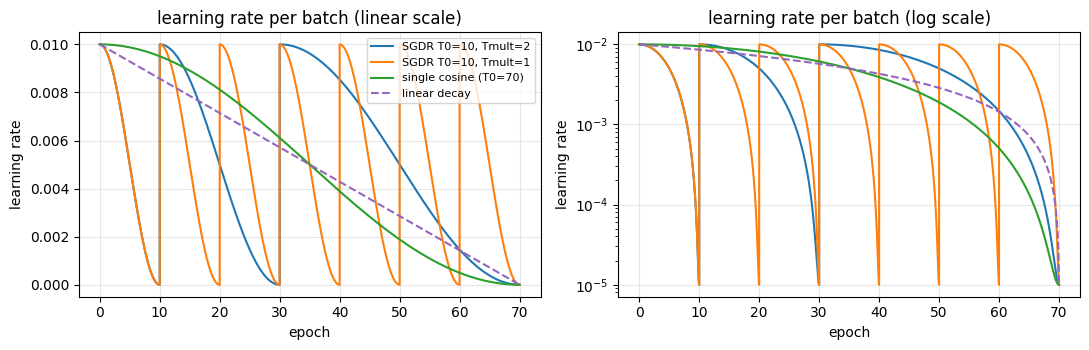

In [5]:
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
import warnings; warnings.filterwarnings("ignore")

def check_against_pytorch(T0, Tmult, ipe=7, eta_min=1e-5):
    p = torch.nn.Parameter(torch.zeros(1))
    opt_mine, opt_ref = torch.optim.SGD([p], lr=0.01), torch.optim.SGD([p], lr=0.01)
    mine = SGDRScheduler(opt_mine, steps_per_epoch=ipe, T_0=T0, T_mult=Tmult, eta_max=0.01, eta_min=eta_min)
    ref = CosineAnnealingWarmRestarts(opt_ref, T_0=T0 * ipe, T_mult=Tmult, eta_min=eta_min)
    n_batches = T0 * (1 + Tmult + Tmult**2 + Tmult**3) * ipe           # four complete cycles
    for k in range(n_batches):
        lr_mine = mine.step()
        lr_ref = opt_ref.param_groups[0]["lr"]
        ref.step()
        assert abs(lr_mine - lr_ref) < 1e-9, f"mismatch at batch {k}: {lr_mine} vs {lr_ref}"
    return n_batches

for T0, Tm in [(1, 2), (10, 2), (10, 1), (3, 3)]:
    print(f"T0={T0:2d}, T_mult={Tm}: identical to CosineAnnealingWarmRestarts for {check_against_pytorch(T0, Tm)} batches")

ipe = len(train_loader)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for label, (T0, Tm) in {"SGDR T0=10, Tmult=2": (10, 2), "SGDR T0=10, Tmult=1": (10, 1), f"single cosine (T0={EPOCHS})": (EPOCHS, 1)}.items():
    s = SGDRScheduler(torch.optim.SGD([torch.nn.Parameter(torch.zeros(1))], lr=LR0), ipe, T0, Tm, LR0, 1e-5)
    lrs = [s.step() for _ in range(EPOCHS * ipe)]
    for a in ax: a.plot(np.arange(len(lrs)) / ipe, lrs, label=label)
lin = [1e-5 + (LR0 - 1e-5) * (1 - k / (EPOCHS * ipe)) for k in range(EPOCHS * ipe)]     # linear-decay baseline
for a in ax: a.plot(np.arange(len(lin)) / ipe, lin, label="linear decay", color="tab:purple", ls="--")
ax[0].legend(fontsize=8); ax[0].set_title("learning rate per batch (linear scale)")
ax[1].set_yscale("log"); ax[1].set_title("learning rate per batch (log scale)")
for a in ax: a.set_xlabel("epoch"); a.set_ylabel("learning rate"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_lr_schedules.png"), dpi=200); plt.show()

In [6]:
@torch.no_grad()
def eval_probs(model, loader):
    model.eval()
    probs, loss_sum = [], 0.0
    for x, y in loader:
        out = model(x)
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        probs.append(F.softmax(out, 1).cpu())
    p = torch.cat(probs).numpy()
    return loss_sum / len(p), p

def log_line(tag, ep, epochs, lr, h, i, ends):
    mark = "  <- cycle end: snapshot" if ep in ends else ""
    print(f"[{tag}] epoch {ep:2d}/{epochs} | lr {lr:.5f} | train loss {h['train_loss'][i]:.3f} acc {h['train_acc'][i]:5.2f}% "
          f"| val loss {h['val_loss'][i]:.3f} acc {h['val_acc'][i]:5.2f}% | {h['sec'][i]:.0f}s{mark}")

def replay(meta, tag):
    """Print the stored log of a finished run (no training)."""
    ends, h, ipe = set(meta["ends"]), meta["hist"], len(train_loader)
    lrb = meta["lr_batches"]
    for ep in range(1, meta["epochs"] + 1):
        if ep % PRINT_EVERY == 0 or ep == 1:
            log_line(tag, ep, meta["epochs"], lrb[ep * ipe - 1], h, ep - 1, ends)

def run(name, method, seed, epochs=EPOCHS, T0=10, Tmult=2, lr0=None, save=True):
    lr0 = LR0 if lr0 is None else lr0
    tag = f"{name}_s{seed}"
    meta_path, npz_path = os.path.join(OUT, tag + ".json"), os.path.join(OUT, tag + ".npz")
    if save and not FORCE_RERUN and os.path.exists(meta_path) and os.path.exists(npz_path):
        print(f"--- {tag}: found on Drive, replaying saved log ---")
        replay(json.load(open(meta_path)), tag); return
    print(f"--- {tag}: training ({method}, eta_max={lr0}, {epochs} epochs) ---")

    set_seed(seed)                                   # same seed -> identical initial weights for every method
    model = make_model().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr0, momentum=0.9, weight_decay=5e-4)

    sched, ends = None, []
    if method == "sgdr":
        sched = SGDRScheduler(opt, len(train_loader), T0, Tmult, eta_max=lr0, eta_min=1e-5)
        ends = cycle_ends(T0, Tmult, epochs)
        if epochs not in ends:
            print(f"WARNING: epoch {epochs} is not a cycle end {ends}; the final model is mid-restart")
    elif method == "step":
        sched = torch.optim.lr_scheduler.MultiStepLR(opt, [round(f * epochs) for f in (.3, .6, .8)], gamma=0.2)

    total_batches = epochs * len(train_loader)
    keep = set(ends) | {epochs - 2, epochs - 1, epochs}   # epochs whose test predictions are stored
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr_mean", "sec"]}
    lr_batches, store = [], {}

    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tl = ok = n = 0
        for x, y in train_loader:
            if method == "sgdr":
                lr = sched.step()                                                 # SGDR is stepped per batch
            elif method == "linear":                                              # straight line eta_max -> ~0 over the whole run
                lr = 1e-5 + (lr0 - 1e-5) * (1 - len(lr_batches) / total_batches)
                for gr in opt.param_groups: gr["lr"] = lr
            else:
                lr = opt.param_groups[0]["lr"]
            lr_batches.append(lr)
            opt.zero_grad()
            out = model(x)
            loss = F.cross_entropy(out, y)
            loss.backward()
            opt.step()
            tl += loss.item() * y.size(0); ok += (out.argmax(1) == y).sum().item(); n += y.size(0)
        if method == "step":
            sched.step()                                                          # step decay is stepped per epoch

        vl, vp = eval_probs(model, val_loader)
        hist["train_loss"].append(tl / n);   hist["train_acc"].append(100 * ok / n)
        hist["val_loss"].append(vl);         hist["val_acc"].append(100 * float((vp.argmax(1) == val_labels).mean()))
        hist["lr_mean"].append(float(np.mean(lr_batches[-len(train_loader):])))
        hist["sec"].append(time.time() - t0)

        if ep in keep:                                   # the test set is only touched at these epochs
            _, tp = eval_probs(model, test_loader)
            store[f"val_{ep}"], store[f"test_{ep}"] = vp.astype(np.float32), tp.astype(np.float32)
            if save and method == "sgdr" and ep in ends:
                torch.save(model.state_dict(), os.path.join(OUT, f"{tag}_snap{ep}.pt"))
        if ep % PRINT_EVERY == 0 or ep == 1 or ep == epochs:
            log_line(tag, ep, epochs, lr_batches[-1], hist, ep - 1, set(ends))

    if save:
        json.dump(dict(name=name, method=method, seed=seed, epochs=epochs, T0=T0, Tmult=Tmult, ends=ends,
                       hist=hist, lr_batches=[round(v, 7) for v in lr_batches]), open(meta_path, "w"))
        np.savez_compressed(npz_path, **store)
    print(f"--- {tag}: done in {sum(hist['sec']) / 60:.1f} min, final val acc {hist['val_acc'][-1]:.2f}% ---\n")
    return hist

# experiment definitions
MAIN = {"const":       dict(method="const"),
        "step":        dict(method="step"),
        "linear":      dict(method="linear"),
        "sgdr_T10_m2": dict(method="sgdr", T0=10, Tmult=2)}
ABL  = {"sgdr_T10_m1": dict(method="sgdr", T0=10, Tmult=1),         # no doubling of the cycle length
        "sgdr_T70_m1": dict(method="sgdr", T0=EPOCHS, Tmult=1)}     # one single cosine cycle, no restarts

ORDER = ["const", "step", "linear", "sgdr_T10_m2", "sgdr_T10_m1", "sgdr_T70_m1",
         "sgdr_T50_m1", "sgdr_T200_m1", "sgdr_T10_m2_e150"]
LABEL = {"const": "constant LR", "step": "step decay", "linear": "linear decay", "sgdr_T10_m2": "SGDR T0=10, Tmult=2",
         "sgdr_T10_m1": "SGDR T0=10, Tmult=1", "sgdr_T70_m1": "single cosine (no restart)",
         "sgdr_T50_m1": "SGDR T0=50, Tmult=1", "sgdr_T200_m1": "single cosine T0=200 (no restart)",
         "sgdr_T10_m2_e150": "SGDR T0=10, Tmult=2 (150 ep.)"}
COLOR = {"const": "gray", "step": "tab:blue", "linear": "tab:purple", "sgdr_T10_m2": "tab:red",
         "sgdr_T10_m1": "tab:green", "sgdr_T70_m1": "tab:orange",
         "sgdr_T50_m1": "tab:brown", "sgdr_T200_m1": "tab:olive", "sgdr_T10_m2_e150": "tab:red"}

def run_schedule(name, group=None, seeds=None):
    """Train (or replay) one schedule for all seeds, printing every epoch, then print a one-line summary."""
    group = MAIN if group is None else group
    seeds = SEEDS if seeds is None else seeds
    for s in seeds:
        run(name, seed=s, **group[name])
    finals = [json.load(open(os.path.join(OUT, f"{name}_s{s}.json")))["hist"]["val_acc"][-1] for s in seeds]
    print(f"===== {LABEL[name]}: final validation accuracy per seed {[round(v, 2) for v in finals]} | median {np.median(finals):.2f}% =====\n")

In [7]:
_PE = PRINT_EVERY; PRINT_EVERY = 1
h = run("smoke", "sgdr", seed=0, epochs=2, T0=1, Tmult=1, save=False)
PRINT_EVERY = _PE
sec = float(np.mean(h["sec"]))
n_runs = len(MAIN) * len(SEEDS) + len(ABL) * len(ABL_SEEDS)
print(f"~{sec:.0f}s/epoch -> one {EPOCHS}-epoch run about {sec * EPOCHS / 60:.0f} min, {n_runs} runs about {sec * EPOCHS * n_runs / 3600:.1f} h in total")

--- smoke_s0: training (sgdr, eta_max=0.01, 2 epochs) ---
[smoke_s0] epoch  1/2 | lr 0.00001 | train loss 1.734 acc 37.22% | val loss 1.443 acc 48.64% | 4s  <- cycle end: snapshot
[smoke_s0] epoch  2/2 | lr 0.00001 | train loss 1.445 acc 48.00% | val loss 1.250 acc 55.90% | 2s  <- cycle end: snapshot
--- smoke_s0: done in 0.1 min, final val acc 55.90% ---

~3s/epoch -> one 70-epoch run about 3 min, 14 runs about 0.8 h in total


In [8]:
run_schedule("const")

--- const_s0: found on Drive, replaying saved log ---
[const_s0] epoch  1/70 | lr 0.01000 | train loss 1.706 acc 38.30% | val loss 1.332 acc 51.58% | 2s
[const_s0] epoch  2/70 | lr 0.01000 | train loss 1.333 acc 52.26% | val loss 1.197 acc 56.86% | 2s
[const_s0] epoch  3/70 | lr 0.01000 | train loss 1.169 acc 58.59% | val loss 1.009 acc 64.72% | 2s
[const_s0] epoch  4/70 | lr 0.01000 | train loss 1.065 acc 62.18% | val loss 0.952 acc 66.74% | 2s
[const_s0] epoch  5/70 | lr 0.01000 | train loss 0.996 acc 64.86% | val loss 0.839 acc 70.90% | 2s
[const_s0] epoch  6/70 | lr 0.01000 | train loss 0.940 acc 66.96% | val loss 0.863 acc 70.86% | 2s
[const_s0] epoch  7/70 | lr 0.01000 | train loss 0.904 acc 68.31% | val loss 0.821 acc 70.98% | 2s
[const_s0] epoch  8/70 | lr 0.01000 | train loss 0.872 acc 69.17% | val loss 0.776 acc 73.66% | 2s
[const_s0] epoch  9/70 | lr 0.01000 | train loss 0.830 acc 70.88% | val loss 0.768 acc 73.86% | 2s
[const_s0] epoch 10/70 | lr 0.01000 | train loss 0.804 

In [9]:
run_schedule("step")

--- step_s0: found on Drive, replaying saved log ---
[step_s0] epoch  1/70 | lr 0.01000 | train loss 1.706 acc 38.29% | val loss 1.337 acc 51.66% | 2s
[step_s0] epoch  2/70 | lr 0.01000 | train loss 1.333 acc 52.15% | val loss 1.183 acc 57.42% | 2s
[step_s0] epoch  3/70 | lr 0.01000 | train loss 1.168 acc 58.77% | val loss 1.015 acc 64.80% | 2s
[step_s0] epoch  4/70 | lr 0.01000 | train loss 1.065 acc 62.20% | val loss 0.981 acc 65.52% | 2s
[step_s0] epoch  5/70 | lr 0.01000 | train loss 0.995 acc 64.87% | val loss 0.840 acc 70.28% | 2s
[step_s0] epoch  6/70 | lr 0.01000 | train loss 0.940 acc 67.04% | val loss 0.865 acc 70.60% | 2s
[step_s0] epoch  7/70 | lr 0.01000 | train loss 0.901 acc 68.37% | val loss 0.816 acc 71.48% | 2s
[step_s0] epoch  8/70 | lr 0.01000 | train loss 0.867 acc 69.46% | val loss 0.766 acc 73.56% | 2s
[step_s0] epoch  9/70 | lr 0.01000 | train loss 0.827 acc 71.06% | val loss 0.767 acc 73.10% | 2s
[step_s0] epoch 10/70 | lr 0.01000 | train loss 0.803 acc 71.81% 

In [10]:
run_schedule("linear")

--- linear_s0: training (linear, eta_max=0.01, 70 epochs) ---
[linear_s0] epoch  1/70 | lr 0.00986 | train loss 1.707 acc 38.22% | val loss 1.334 acc 51.74% | 2s
[linear_s0] epoch  2/70 | lr 0.00971 | train loss 1.333 acc 52.20% | val loss 1.189 acc 56.96% | 2s
[linear_s0] epoch  3/70 | lr 0.00957 | train loss 1.170 acc 58.59% | val loss 1.011 acc 64.82% | 2s
[linear_s0] epoch  4/70 | lr 0.00943 | train loss 1.067 acc 62.01% | val loss 0.959 acc 66.48% | 2s
[linear_s0] epoch  5/70 | lr 0.00929 | train loss 0.999 acc 64.72% | val loss 0.843 acc 70.22% | 2s
[linear_s0] epoch  6/70 | lr 0.00914 | train loss 0.942 acc 66.84% | val loss 0.875 acc 70.04% | 2s
[linear_s0] epoch  7/70 | lr 0.00900 | train loss 0.904 acc 68.21% | val loss 0.810 acc 72.00% | 2s
[linear_s0] epoch  8/70 | lr 0.00886 | train loss 0.870 acc 69.27% | val loss 0.772 acc 74.00% | 2s
[linear_s0] epoch  9/70 | lr 0.00872 | train loss 0.830 acc 70.88% | val loss 0.750 acc 74.00% | 2s
[linear_s0] epoch 10/70 | lr 0.00857 |

In [12]:
run_schedule("sgdr_T10_m2")

--- sgdr_T10_m2_s0: found on Drive, replaying saved log ---
[sgdr_T10_m2_s0] epoch  1/70 | lr 0.00976 | train loss 1.706 acc 38.28% | val loss 1.334 acc 51.98% | 2s
[sgdr_T10_m2_s0] epoch  2/70 | lr 0.00905 | train loss 1.333 acc 52.18% | val loss 1.184 acc 57.46% | 2s
[sgdr_T10_m2_s0] epoch  3/70 | lr 0.00794 | train loss 1.169 acc 58.60% | val loss 0.986 acc 65.62% | 2s
[sgdr_T10_m2_s0] epoch  4/70 | lr 0.00655 | train loss 1.065 acc 62.35% | val loss 0.940 acc 67.38% | 2s
[sgdr_T10_m2_s0] epoch  5/70 | lr 0.00501 | train loss 0.994 acc 65.03% | val loss 0.845 acc 70.68% | 2s
[sgdr_T10_m2_s0] epoch  6/70 | lr 0.00347 | train loss 0.931 acc 67.29% | val loss 0.838 acc 71.08% | 2s
[sgdr_T10_m2_s0] epoch  7/70 | lr 0.00207 | train loss 0.893 acc 68.67% | val loss 0.790 acc 72.80% | 2s
[sgdr_T10_m2_s0] epoch  8/70 | lr 0.00097 | train loss 0.857 acc 69.99% | val loss 0.791 acc 72.82% | 2s
[sgdr_T10_m2_s0] epoch  9/70 | lr 0.00026 | train loss 0.831 acc 70.94% | val loss 0.771 acc 73.40% 

In [11]:
for seed in ABL_SEEDS:
    for name, cfg in ABL.items():
        run(name, seed=seed, **cfg)

--- sgdr_T10_m1_s0: found on Drive, replaying saved log ---
[sgdr_T10_m1_s0] epoch  1/70 | lr 0.00976 | train loss 1.705 acc 38.39% | val loss 1.334 acc 51.54% | 2s
[sgdr_T10_m1_s0] epoch  2/70 | lr 0.00905 | train loss 1.333 acc 52.24% | val loss 1.196 acc 56.96% | 2s
[sgdr_T10_m1_s0] epoch  3/70 | lr 0.00794 | train loss 1.169 acc 58.56% | val loss 0.980 acc 65.80% | 2s
[sgdr_T10_m1_s0] epoch  4/70 | lr 0.00655 | train loss 1.065 acc 62.31% | val loss 0.934 acc 67.88% | 2s
[sgdr_T10_m1_s0] epoch  5/70 | lr 0.00501 | train loss 0.996 acc 64.92% | val loss 0.846 acc 70.50% | 2s
[sgdr_T10_m1_s0] epoch  6/70 | lr 0.00347 | train loss 0.932 acc 67.24% | val loss 0.838 acc 71.10% | 2s
[sgdr_T10_m1_s0] epoch  7/70 | lr 0.00207 | train loss 0.895 acc 68.73% | val loss 0.791 acc 72.84% | 2s
[sgdr_T10_m1_s0] epoch  8/70 | lr 0.00097 | train loss 0.858 acc 69.92% | val loss 0.790 acc 72.96% | 2s
[sgdr_T10_m1_s0] epoch  9/70 | lr 0.00026 | train loss 0.832 acc 70.88% | val loss 0.771 acc 73.92% 

In [13]:
R = {}                                    # (run name, seed) -> metadata + stored predictions
def load_results():
    global R
    R = {}
    for f in sorted(os.listdir(OUT)):
        if f.endswith(".json"):
            meta = json.load(open(os.path.join(OUT, f)))
            z = np.load(os.path.join(OUT, f.replace(".json", ".npz")))
            R[(meta["name"], meta["seed"])] = dict(meta=meta, p={k: z[k] for k in z.files})
    print(f"loaded {len(R)} runs from {OUT}")

def core_names():  return [n for n in ORDER if any(m == n for m, _ in R)]
def seeds_of(n):   return sorted(s for m, s in R if m == n)
def err(p, y):     return 100.0 * float((p.argmax(1) != y).mean())
def final_test_err(n, s):
    return err(R[(n, s)]["p"][f"test_{R[(n, s)]['meta']['epochs']}"], test_labels)

def rec_curve(meta, key="val_acc"):
    """Paper's 'recommended solution': current weights during the first run, afterwards the weights of the last finished run."""
    acc, ends, last, out = meta["hist"][key], set(meta["ends"]), None, []
    for ep, a in enumerate(acc, 1):
        if ep in ends: last = a
        out.append(a if last is None else last)
    return out

PAPER = {"step": 4.13, "sgdr_T10_m2": 4.03}      # paper, WRN-28-10 on CIFAR-10, test error %, Table 1

def show_table():
    rows = []
    for n in core_names():
        te = [final_test_err(n, s) for s in seeds_of(n)]
        ve = [100 - R[(n, s)]["meta"]["hist"]["val_acc"][-1] for s in seeds_of(n)]
        rows.append({"schedule": LABEL[n], "seeds": len(te), "val error % (median)": np.median(ve),
                     "test error % (median)": np.median(te), "test min": min(te), "test max": max(te)})
    display(pd.DataFrame(rows).round(2).set_index("schedule"))
    print("for reference, the paper (WRN-28-10, 200 epochs) reports 4.13% (step) and 4.03% (SGDR T0=10, Tmult=2).")
    print("absolute numbers are not comparable (smaller model, shorter training); the comparison is about the trends.")

def show_bars():
    """Final test error of every schedule: bar = median over seeds, dots = individual seeds."""
    ns = core_names(); vals = [[final_test_err(n, s) for s in seeds_of(n)] for n in ns]
    plt.figure(figsize=(8, 4))
    plt.bar(range(len(ns)), [np.median(v) for v in vals], color=[COLOR[n] for n in ns], alpha=.8)
    for i, v in enumerate(vals): plt.scatter([i] * len(v), v, color="k", s=14, zorder=3)
    plt.xticks(range(len(ns)), [LABEL[n].replace(" (", "\n(") for n in ns], fontsize=8)
    plt.ylabel("test error (%)"); plt.grid(axis="y", alpha=.3)
    plt.ylim(max(0, min(map(min, vals)) - 2), max(map(max, vals)) + 1)
    plt.title("Final test error by learning-rate schedule"); plt.tight_layout()
    plt.savefig(os.path.join(OUT, "fig_final_comparison.png"), dpi=200); plt.show()

def show_curves():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for n in core_names():
        cur = np.array([100 - np.array(R[(n, s)]["meta"]["hist"]["val_acc"]) for s in seeds_of(n)])
        rec = np.array([100 - np.array(rec_curve(R[(n, s)]["meta"])) for s in seeds_of(n)])
        ep = np.arange(1, cur.shape[1] + 1)
        for a, c in ((ax[0], cur), (ax[1], rec)):
            a.plot(ep, np.median(c, 0), label=LABEL[n], color=COLOR[n])
            if len(c) > 1: a.fill_between(ep, c.min(0), c.max(0), color=COLOR[n], alpha=.15)
    ax[0].set_title("validation error of the current weights"); ax[1].set_title("validation error of the recommended solution")
    for a in ax: a.set_xlabel("epoch"); a.set_ylabel("validation error (%)"); a.grid(alpha=.3); a.set_ylim(None, 45)
    ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_val_error.png"), dpi=200); plt.show()

    # anytime performance: first epoch where the recommended val error is within 1 point of the step baseline's final error
    tgt = np.median([100 - R[("step", s)]["meta"]["hist"]["val_acc"][-1] for s in seeds_of("step")]) + 1.0
    rows = {}
    for n in core_names():
        e = [next((i for i, v in enumerate(100 - np.array(rec_curve(R[(n, s)]["meta"])), 1) if v <= tgt), None) for s in seeds_of(n)]
        rows[LABEL[n]] = e
    print(f"epoch at which the recommended validation error first reaches <= {tgt:.2f}% (one entry per seed; None = never):")
    display(pd.DataFrame.from_dict(rows, orient="index", columns=[f"seed {s}" for s in seeds_of(core_names()[0])]))

loaded 14 runs from /content/drive/MyDrive/SGDR_Project/v2


,seeds,val error % (median),test error % (median),test min,test max
schedule,,,,,
constant LR,3,18.82,18.91,18.06,18.93
step decay,3,17.46,17.56,17.40,17.68
linear decay,3,16.50,16.85,16.78,16.99
"SGDR T0=10, Tmult=2",3,16.54,16.83,16.77,17.30
"SGDR T0=10, Tmult=1",1,16.88,17.30,17.30,17.30
single cosine (no restart),1,16.50,16.69,16.69,16.69


for reference, the paper (WRN-28-10, 200 epochs) reports 4.13% (step) and 4.03% (SGDR T0=10, Tmult=2).
absolute numbers are not comparable (smaller model, shorter training); the comparison is about the trends.


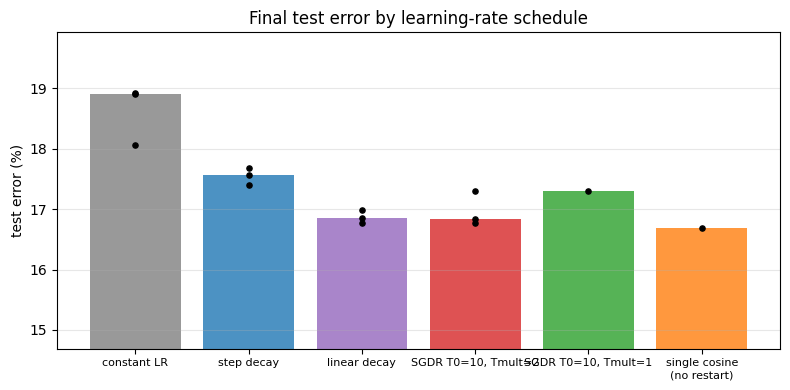

In [14]:
load_results()
show_table()
show_bars()

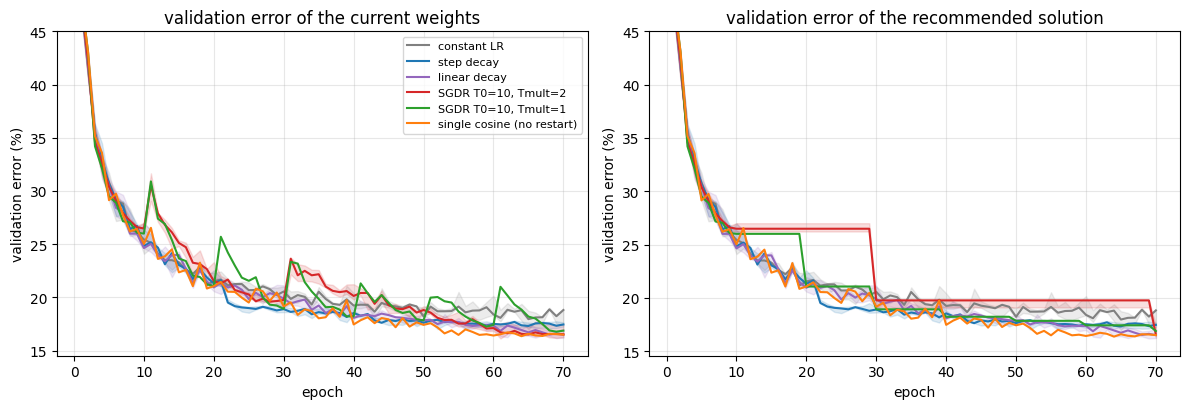

epoch at which the recommended validation error first reaches <= 18.46% (one entry per seed; None = never):


,seed 0,seed 1,seed 2
constant LR,48,61.0,43.0
step decay,34,33.0,32.0
linear decay,36,38.0,38.0
"SGDR T0=10, Tmult=2",70,70.0,70.0
"SGDR T0=10, Tmult=1",40,NaN,NaN
single cosine (no restart),32,NaN,NaN


In [15]:
show_curves()

In [16]:
rows = []
for n in core_names():
    te = [final_test_err(n, s) for s in seeds_of(n)]
    rows.append({"schedule": LABEL[n], "cycle ends": R[(n, seeds_of(n)[0])]["meta"]["ends"] or "-",
                 "seeds": len(te), "test error % (median)": np.median(te)})
display(pd.DataFrame(rows).round(2).set_index("schedule"))

,cycle ends,seeds,test error % (median)
schedule,,,
constant LR,-,3,18.91
step decay,-,3,17.56
linear decay,-,3,16.85
"SGDR T0=10, Tmult=2","[10, 30, 70]",3,16.83
"SGDR T0=10, Tmult=1","[10, 20, 30, 40, 50, 60, 70]",1,17.30
single cosine (no restart),[70],1,16.69


In [18]:
use_setup("cnn", 0.01)
OUT = os.path.join(PROJECT_DIR, "v2_200ep"); os.makedirs(OUT, exist_ok=True)   # separate folder for the 200-epoch runs
SEEDS200, EPOCHS200 = [0], 200        # start with one seed; add 1 and 2 later (run_schedule skips what is already saved)

EXP200 = {
    "const":            dict(method="const",  epochs=EPOCHS200),
    "step":             dict(method="step",   epochs=EPOCHS200),                    # x0.2 at epochs 60 / 120 / 160
    "linear":           dict(method="linear", epochs=EPOCHS200),
    "sgdr_T50_m1":      dict(method="sgdr", T0=50,  Tmult=1, epochs=EPOCHS200),     # cycle ends 50, 100, 150, 200
    "sgdr_T200_m1":     dict(method="sgdr", T0=200, Tmult=1, epochs=EPOCHS200),     # single cosine cycle, no restart
    "sgdr_T10_m2_e150": dict(method="sgdr", T0=10,  Tmult=2, epochs=150),           # cycle ends 10, 30, 70, 150 (paper's ensemble setting)
}
for n, c in EXP200.items():
    if c["method"] == "sgdr": print(f"{LABEL[n]:34s} cycle ends at epochs {cycle_ends(c['T0'], c['Tmult'], c['epochs'])}")
epochs_per_seed = sum(c["epochs"] for c in EXP200.values())
if "sec" in globals():
    print(f"\nabout {sec * epochs_per_seed / 3600:.1f} h per seed at {sec:.0f}s/epoch (from the timing test)")

setup: arch=cnn, eta_max=0.01, results folder=/content/drive/MyDrive/SGDR_Project/v2
SGDR T0=50, Tmult=1                cycle ends at epochs [50, 100, 150, 200]
single cosine T0=200 (no restart)  cycle ends at epochs [200]
SGDR T0=10, Tmult=2 (150 ep.)      cycle ends at epochs [10, 30, 70, 150]

about 0.9 h per seed at 3s/epoch (from the timing test)


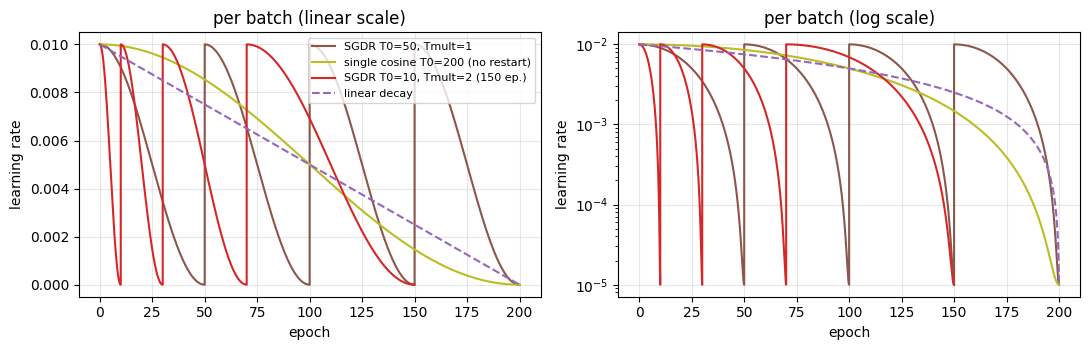

In [19]:
# learning-rate schedules of the 200-epoch experiment (per batch)
ipe = len(train_loader)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for n in ["sgdr_T50_m1", "sgdr_T200_m1", "sgdr_T10_m2_e150"]:
    c = EXP200[n]
    s_ = SGDRScheduler(torch.optim.SGD([torch.nn.Parameter(torch.zeros(1))], lr=LR0), ipe, c["T0"], c["Tmult"], LR0, 1e-5)
    lrs = [s_.step() for _ in range(c["epochs"] * ipe)]
    for a in ax: a.plot(np.arange(len(lrs)) / ipe, lrs, label=LABEL[n], color=COLOR[n])
lin = [1e-5 + (LR0 - 1e-5) * (1 - k / (EPOCHS200 * ipe)) for k in range(EPOCHS200 * ipe)]
for a in ax: a.plot(np.arange(len(lin)) / ipe, lin, label="linear decay", color="tab:purple", ls="--")
ax[0].legend(fontsize=8); ax[0].set_title("per batch (linear scale)")
ax[1].set_yscale("log"); ax[1].set_title("per batch (log scale)")
for a in ax: a.set_xlabel("epoch"); a.set_ylabel("learning rate"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_lr_schedules_200.png"), dpi=200); plt.show()

In [20]:
run_schedule("const", EXP200, SEEDS200)

--- const_s0: training (const, eta_max=0.01, 200 epochs) ---
[const_s0] epoch  1/200 | lr 0.01000 | train loss 1.706 acc 38.25% | val loss 1.335 acc 51.68% | 2s
[const_s0] epoch  2/200 | lr 0.01000 | train loss 1.333 acc 52.24% | val loss 1.196 acc 56.62% | 2s
[const_s0] epoch  3/200 | lr 0.01000 | train loss 1.168 acc 58.73% | val loss 1.010 acc 64.64% | 2s
[const_s0] epoch  4/200 | lr 0.01000 | train loss 1.066 acc 62.12% | val loss 0.977 acc 65.70% | 2s
[const_s0] epoch  5/200 | lr 0.01000 | train loss 0.995 acc 64.83% | val loss 0.843 acc 70.28% | 2s
[const_s0] epoch  6/200 | lr 0.01000 | train loss 0.940 acc 66.83% | val loss 0.871 acc 70.34% | 2s
[const_s0] epoch  7/200 | lr 0.01000 | train loss 0.903 acc 68.34% | val loss 0.825 acc 71.24% | 2s
[const_s0] epoch  8/200 | lr 0.01000 | train loss 0.871 acc 69.14% | val loss 0.776 acc 73.80% | 2s
[const_s0] epoch  9/200 | lr 0.01000 | train loss 0.827 acc 70.88% | val loss 0.762 acc 73.44% | 2s
[const_s0] epoch 10/200 | lr 0.01000 | 

In [21]:
run_schedule("step", EXP200, SEEDS200)

--- step_s0: training (step, eta_max=0.01, 200 epochs) ---
[step_s0] epoch  1/200 | lr 0.01000 | train loss 1.706 acc 38.24% | val loss 1.334 acc 51.60% | 2s
[step_s0] epoch  2/200 | lr 0.01000 | train loss 1.334 acc 52.12% | val loss 1.204 acc 56.46% | 2s
[step_s0] epoch  3/200 | lr 0.01000 | train loss 1.169 acc 58.58% | val loss 1.009 acc 64.90% | 2s
[step_s0] epoch  4/200 | lr 0.01000 | train loss 1.067 acc 62.06% | val loss 0.955 acc 66.42% | 2s
[step_s0] epoch  5/200 | lr 0.01000 | train loss 0.997 acc 64.80% | val loss 0.839 acc 70.72% | 2s
[step_s0] epoch  6/200 | lr 0.01000 | train loss 0.940 acc 66.92% | val loss 0.860 acc 70.94% | 2s
[step_s0] epoch  7/200 | lr 0.01000 | train loss 0.903 acc 68.35% | val loss 0.818 acc 71.46% | 2s
[step_s0] epoch  8/200 | lr 0.01000 | train loss 0.870 acc 69.14% | val loss 0.763 acc 73.52% | 2s
[step_s0] epoch  9/200 | lr 0.01000 | train loss 0.831 acc 70.80% | val loss 0.763 acc 73.42% | 2s
[step_s0] epoch 10/200 | lr 0.01000 | train loss 0

In [22]:
run_schedule("linear", EXP200, SEEDS200)

--- linear_s0: training (linear, eta_max=0.01, 200 epochs) ---
[linear_s0] epoch  1/200 | lr 0.00995 | train loss 1.706 acc 38.30% | val loss 1.334 acc 51.48% | 2s
[linear_s0] epoch  2/200 | lr 0.00990 | train loss 1.333 acc 52.18% | val loss 1.202 acc 56.44% | 2s
[linear_s0] epoch  3/200 | lr 0.00985 | train loss 1.168 acc 58.58% | val loss 1.011 acc 64.86% | 2s
[linear_s0] epoch  4/200 | lr 0.00980 | train loss 1.066 acc 61.99% | val loss 0.973 acc 66.44% | 2s
[linear_s0] epoch  5/200 | lr 0.00975 | train loss 0.995 acc 64.93% | val loss 0.842 acc 70.70% | 2s
[linear_s0] epoch  6/200 | lr 0.00970 | train loss 0.939 acc 66.98% | val loss 0.870 acc 70.58% | 2s
[linear_s0] epoch  7/200 | lr 0.00965 | train loss 0.901 acc 68.52% | val loss 0.816 acc 71.96% | 2s
[linear_s0] epoch  8/200 | lr 0.00960 | train loss 0.869 acc 69.30% | val loss 0.763 acc 74.30% | 2s
[linear_s0] epoch  9/200 | lr 0.00955 | train loss 0.829 acc 70.70% | val loss 0.752 acc 74.18% | 2s
[linear_s0] epoch 10/200 | l

In [23]:
run_schedule("sgdr_T50_m1", EXP200, SEEDS200)

--- sgdr_T50_m1_s0: training (sgdr, eta_max=0.01, 200 epochs) ---
[sgdr_T50_m1_s0] epoch  1/200 | lr 0.00999 | train loss 1.707 acc 38.22% | val loss 1.328 acc 51.92% | 2s
[sgdr_T50_m1_s0] epoch  2/200 | lr 0.00996 | train loss 1.333 acc 52.26% | val loss 1.183 acc 57.14% | 2s
[sgdr_T50_m1_s0] epoch  3/200 | lr 0.00991 | train loss 1.168 acc 58.66% | val loss 1.016 acc 64.80% | 2s
[sgdr_T50_m1_s0] epoch  4/200 | lr 0.00984 | train loss 1.067 acc 61.97% | val loss 0.954 acc 67.10% | 2s
[sgdr_T50_m1_s0] epoch  5/200 | lr 0.00976 | train loss 0.997 acc 64.96% | val loss 0.846 acc 70.34% | 2s
[sgdr_T50_m1_s0] epoch  6/200 | lr 0.00965 | train loss 0.938 acc 66.99% | val loss 0.886 acc 69.42% | 2s
[sgdr_T50_m1_s0] epoch  7/200 | lr 0.00952 | train loss 0.901 acc 68.45% | val loss 0.820 acc 71.60% | 3s
[sgdr_T50_m1_s0] epoch  8/200 | lr 0.00938 | train loss 0.867 acc 69.33% | val loss 0.768 acc 73.52% | 2s
[sgdr_T50_m1_s0] epoch  9/200 | lr 0.00922 | train loss 0.826 acc 70.95% | val loss 0.

In [24]:
run_schedule("sgdr_T200_m1", EXP200, SEEDS200)

--- sgdr_T200_m1_s0: training (sgdr, eta_max=0.01, 200 epochs) ---
[sgdr_T200_m1_s0] epoch  1/200 | lr 0.01000 | train loss 1.706 acc 38.27% | val loss 1.332 acc 51.78% | 2s
[sgdr_T200_m1_s0] epoch  2/200 | lr 0.01000 | train loss 1.334 acc 52.15% | val loss 1.192 acc 57.12% | 2s
[sgdr_T200_m1_s0] epoch  3/200 | lr 0.00999 | train loss 1.170 acc 58.59% | val loss 1.004 acc 64.98% | 2s
[sgdr_T200_m1_s0] epoch  4/200 | lr 0.00999 | train loss 1.066 acc 62.12% | val loss 0.975 acc 65.52% | 2s
[sgdr_T200_m1_s0] epoch  5/200 | lr 0.00998 | train loss 0.995 acc 64.92% | val loss 0.841 acc 70.36% | 2s
[sgdr_T200_m1_s0] epoch  6/200 | lr 0.00998 | train loss 0.941 acc 67.01% | val loss 0.871 acc 70.78% | 2s
[sgdr_T200_m1_s0] epoch  7/200 | lr 0.00997 | train loss 0.905 acc 68.14% | val loss 0.819 acc 71.66% | 2s
[sgdr_T200_m1_s0] epoch  8/200 | lr 0.00996 | train loss 0.868 acc 69.36% | val loss 0.777 acc 73.70% | 2s
[sgdr_T200_m1_s0] epoch  9/200 | lr 0.00995 | train loss 0.831 acc 70.82% | v

In [25]:
run_schedule("sgdr_T10_m2_e150", EXP200, SEEDS200)

--- sgdr_T10_m2_e150_s0: training (sgdr, eta_max=0.01, 150 epochs) ---
[sgdr_T10_m2_e150_s0] epoch  1/150 | lr 0.00976 | train loss 1.706 acc 38.35% | val loss 1.336 acc 51.64% | 2s
[sgdr_T10_m2_e150_s0] epoch  2/150 | lr 0.00905 | train loss 1.333 acc 52.27% | val loss 1.177 acc 57.68% | 2s
[sgdr_T10_m2_e150_s0] epoch  3/150 | lr 0.00794 | train loss 1.167 acc 58.57% | val loss 0.982 acc 65.98% | 2s
[sgdr_T10_m2_e150_s0] epoch  4/150 | lr 0.00655 | train loss 1.063 acc 62.36% | val loss 0.935 acc 67.64% | 2s
[sgdr_T10_m2_e150_s0] epoch  5/150 | lr 0.00501 | train loss 0.995 acc 64.95% | val loss 0.847 acc 70.52% | 2s
[sgdr_T10_m2_e150_s0] epoch  6/150 | lr 0.00347 | train loss 0.931 acc 67.28% | val loss 0.838 acc 70.90% | 2s
[sgdr_T10_m2_e150_s0] epoch  7/150 | lr 0.00207 | train loss 0.894 acc 68.84% | val loss 0.788 acc 72.36% | 2s
[sgdr_T10_m2_e150_s0] epoch  8/150 | lr 0.00097 | train loss 0.858 acc 69.93% | val loss 0.789 acc 72.96% | 2s
[sgdr_T10_m2_e150_s0] epoch  9/150 | lr 0

loaded 6 runs from /content/drive/MyDrive/SGDR_Project/v2_200ep


,seeds,val error % (median),test error % (median),test min,test max
schedule,,,,,
constant LR,1,18.48,18.49,18.49,18.49
step decay,1,15.94,15.80,15.80,15.80
linear decay,1,16.02,15.99,15.99,15.99
"SGDR T0=50, Tmult=1",1,15.60,15.78,15.78,15.78
single cosine T0=200 (no restart),1,16.00,16.03,16.03,16.03
"SGDR T0=10, Tmult=2 (150 ep.)",1,15.56,16.24,16.24,16.24


for reference, the paper (WRN-28-10, 200 epochs) reports 4.13% (step) and 4.03% (SGDR T0=10, Tmult=2).
absolute numbers are not comparable (smaller model, shorter training); the comparison is about the trends.


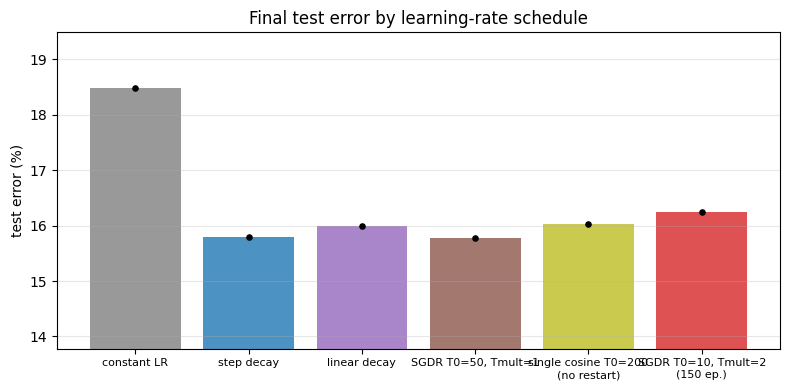

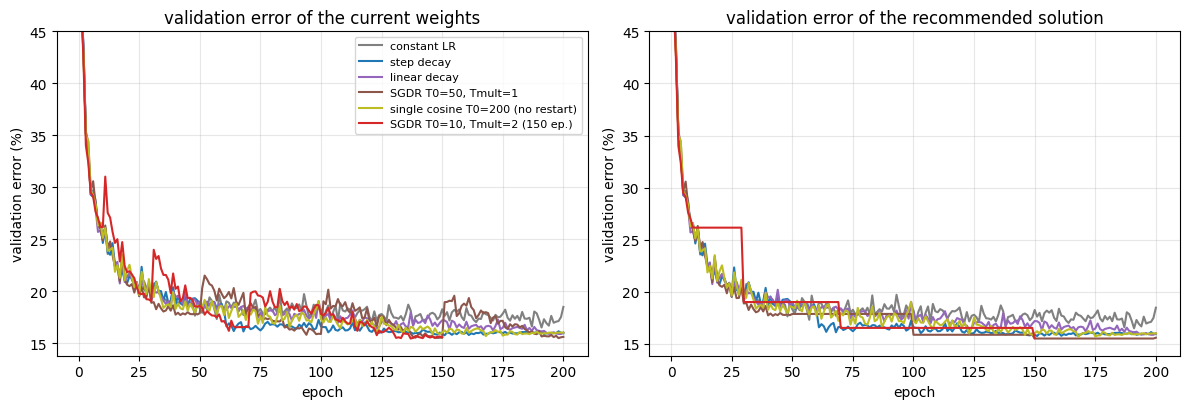

epoch at which the recommended validation error first reaches <= 16.94% (one entry per seed; None = never):


,seed 0
constant LR,138
step decay,61
linear decay,115
"SGDR T0=50, Tmult=1",100
single cosine T0=200 (no restart),74
"SGDR T0=10, Tmult=2 (150 ep.)",70


NameError: name 'show_ensembles' is not defined

In [27]:
load_results()
show_table()
show_bars()
show_curves()
show_ensembles("sgdr_T10_m2_e150")
show_ensembles("sgdr_T50_m1")

setup: arch=cnn, eta_max=0.01, results folder=/content/drive/MyDrive/SGDR_Project/v2
--- step_lr0.003_s0: training (step, eta_max=0.003, 70 epochs) ---
[step_lr0.003_s0] epoch  1/70 | lr 0.00300 | train loss 1.945 acc 30.02% | val loss 1.590 acc 43.58% | 2s
[step_lr0.003_s0] epoch  2/70 | lr 0.00300 | train loss 1.543 acc 44.34% | val loss 1.391 acc 51.14% | 2s
[step_lr0.003_s0] epoch  3/70 | lr 0.00300 | train loss 1.409 acc 49.36% | val loss 1.260 acc 55.04% | 2s
[step_lr0.003_s0] epoch  4/70 | lr 0.00300 | train loss 1.317 acc 52.93% | val loss 1.174 acc 58.68% | 2s
[step_lr0.003_s0] epoch  5/70 | lr 0.00300 | train loss 1.246 acc 55.75% | val loss 1.082 acc 61.58% | 2s
[step_lr0.003_s0] epoch  6/70 | lr 0.00300 | train loss 1.178 acc 58.27% | val loss 1.028 acc 64.36% | 2s
[step_lr0.003_s0] epoch  7/70 | lr 0.00300 | train loss 1.126 acc 60.42% | val loss 0.972 acc 65.72% | 2s
[step_lr0.003_s0] epoch  8/70 | lr 0.00300 | train loss 1.071 acc 62.06% | val loss 0.939 acc 67.60% | 2s


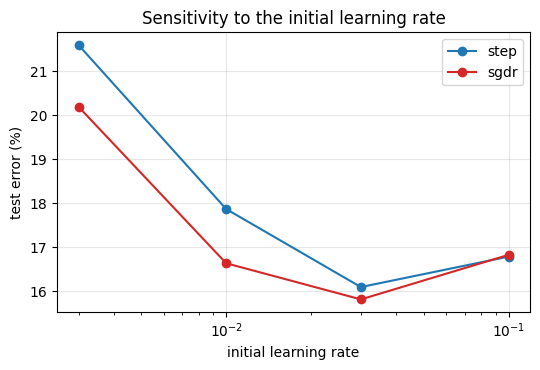

In [28]:
use_setup("cnn", 0.01)
LRS = [0.003, 0.01, 0.03, 0.1]
for lr in LRS:
    for seed in SEEDS:
        run(f"step_lr{lr}", "step", seed, lr0=lr)
        run(f"sgdr_lr{lr}", "sgdr", seed, T0=10, Tmult=2, lr0=lr)

load_results()
plt.figure(figsize=(5.5, 3.8))
for m, c in (("step", "tab:blue"), ("sgdr", "tab:red")):
    med = [np.median([final_test_err(f"{m}_lr{lr}", s) for s in seeds_of(f"{m}_lr{lr}")]) for lr in LRS]
    plt.plot(LRS, med, "o-", color=c, label=m)
plt.xscale("log"); plt.xlabel("initial learning rate"); plt.ylabel("test error (%)"); plt.grid(alpha=.3); plt.legend()
plt.title("Sensitivity to the initial learning rate"); plt.tight_layout()
plt.savefig(os.path.join(OUT, "fig_lr_sensitivity.png"), dpi=200); plt.show()